# Assignment 2
#### Casey Elizabeth Gilbert

In [80]:
# import a bunch of stuff
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from matplotlib import rc
import time
import random
import math
from collections import Counter

## Question 1

#### Question 1a

In [95]:
def grow_barabasi_albert_net(N, m):
    """
    This function creates a scale-free network using barabasi-albert model.

    It loops through and adds the proper amount of nodes (specified as param).
    For each node, it connects via m links to existing nodes. 

    NOTES:
    Adds links with preferential attachment, the preferential attachment comes from choosing a random edge.
    So a node with twice as many edges is twice as likely to have an edge chosen.
    Because degree = edge count * 2, th probability for each node is then halved
    This is taken care of when we randomly select one of the edge's nodes.
    
    This doesn't allow self loops, and isn't exactly LCD, but it is computationally cleaner,
    and I think should create scale-free networks.

    @param N (int): The number of nodes
    @param m (int): Number of edges formed for each new node

    @return the scale-free network
    @return an array of degree sequences at N^x
    """

    degree_sequences = []

    simple_graph = nx.complete_graph(4)

    start_graph = nx.MultiGraph(simple_graph)
     
    t = 5

    # get our order of magnitude so we know what to print
    o_of_m = int(math.log10(N))

    degree_sequences_vals = []
    if (o_of_m > 1):
        for i in range(2,o_of_m + 1):
            degree_sequences_vals.append(10**i)
    print(degree_sequences_vals)
    while t < N:
        t = t + 1

        # add node
        start_graph.add_node(t)

        # we don't want to accidentally select the new node's edge,
        # so we get the edge list ahead of time
        edge_list = list(start_graph.edges) 

        # Now add the m edges
        for i in range(0,m):
            # get random edge
            chosen_edge = edge_list[random.randint(0,len(edge_list)-1)]
            #print(f"chosen_edge: {chosen_edge}")

            #randomly choose one edge of that link
            chosen_node = chosen_edge[random.randint(0,1)]
            #print(f"Chosen node: {chosen_node}")

            # attach the new edge 
            start_graph.add_edge(t, chosen_node)

        if t in degree_sequences_vals:
            degree_seq = np.array(list(dict(start_graph.degree()).values()))
            degree_sequences.append(degree_seq)


    return start_graph, degree_sequences
    

[100]


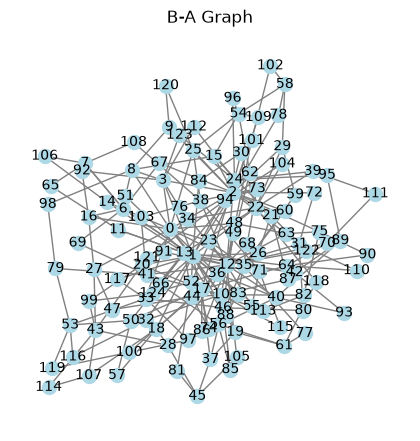

In [96]:
N = 10**4
m = 4
# Just test it with smaller numbers to see what's up
G, degree_dists = grow_barabasi_albert_net(124,2)

plt.figure(figsize=(4, 4))
nx.draw(G, with_labels=True, node_color='lightblue', edge_color='gray', node_size=100, font_size=10)
plt.title("B-A Graph")
plt.show()

In [ ]:
N = 10**4
m = 4
# Just test it with smaller numbers to see what's up
G, degree_dists = grow_barabasi_albert_net(N,m)

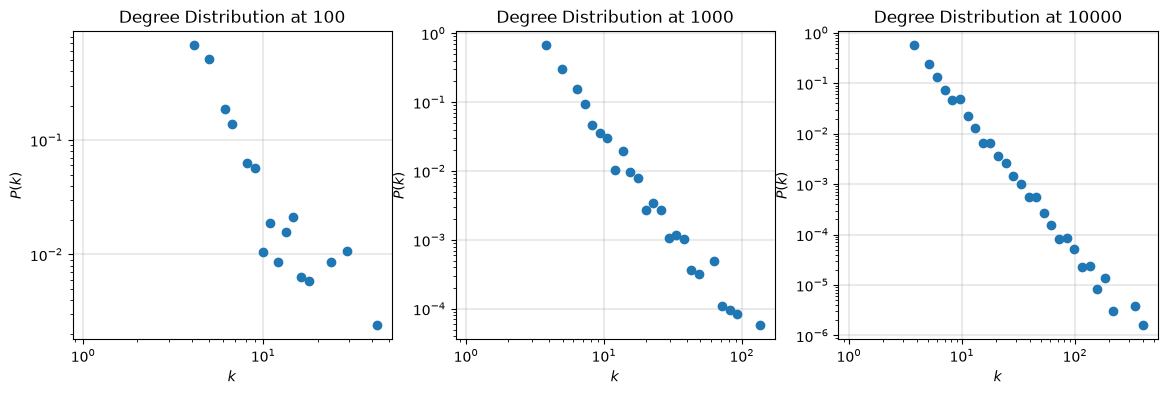

In [110]:
fig, ax = plt.subplots(1,len(degree_dists),figsize=(14,4),dpi=100)

for i in range(0, len(degree_dists)):
    # get nice binned distributions 
    deg_vals = degree_dists[i]
    deg_bins = np.logspace(0, np.log10(np.max(deg_vals)+1), num=40)
    probs, _ = np.histogram(deg_vals, bins=deg_bins, density=True)
    final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

    # plot that puppy
    ax[i].loglog(final_bins, probs, marker='o',lw=0)
    ax[i].set_xlabel(r"$k$", fontsize='medium')
    ax[i].set_ylabel(r"$P(k)$", fontsize='medium')
    ax[i].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')
    ax[i].set_title(f'Degree Distribution at {10**(i+2)}', fontsize='large')

plt.show()

#### Question 1b

In [115]:
import powerlaw

for i,dist in enumerate(degree_dists):
    print(f"Dist: {10**(i+2)}")
    fit = powerlaw.Fit(dist)

    print(fit.power_law.alpha)
    print(fit.power_law.xmin)

Dist: 100
3.286730831375987
5.0
Dist: 1000
3.0679175888358685
12.0
Dist: 10000
3.0107269949036817
17.0


Calculating best minimal value for power law fit
Calculating best minimal value for power law fit
Calculating best minimal value for power law fit


Calculating best minimal value for power law fit
/var/folders/3n/4c447n7j2yv7hw5yxxvb35880000gn/T/ipykernel_61780/426818587.py:18: UserWarning: Legend does not support handles for float64 instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/users/explain/axes/legend_guide.html#controlling-the-legend-entries
  ax[i].legend([fit.power_law.alpha, fit.power_law.xmin], ['γ', 'k-min'], fontsize='small')
Calculating best minimal value for power law fit
Calculating best minimal value for power law fit


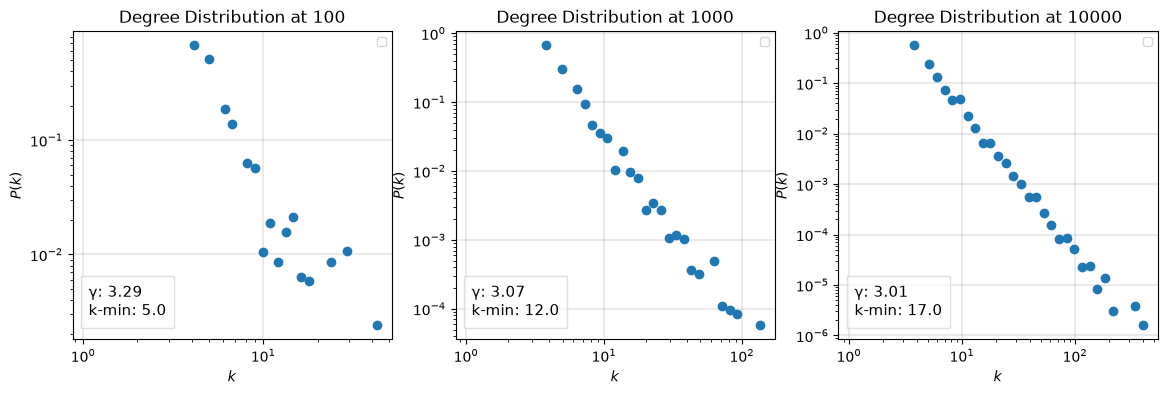

In [145]:
fig, ax = plt.subplots(1,len(degree_dists),figsize=(14,4),dpi=100)

for i,dist in enumerate(degree_dists):
    # fit the distribution
    fit = powerlaw.Fit(dist)

    # get nice binned distributions 
    deg_vals = degree_dists[i]
    deg_bins = np.logspace(0, np.log10(np.max(deg_vals)+1), num=40)
    probs, _ = np.histogram(deg_vals, bins=deg_bins, density=True)
    final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

    # plot that puppy
    ax[i].loglog(final_bins, probs, marker='o',lw=0)
    ax[i].set_xlabel(r"$k$", fontsize='medium')
    ax[i].set_ylabel(r"$P(k)$", fontsize='medium')
    ax[i].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')
    ax[i].legend([fit.power_law.alpha, fit.power_law.xmin], ['γ', 'k-min'], fontsize='small')
    ax[i].set_title(f'Degree Distribution at {10**(i+2)}', fontsize='large')

    box_style = dict(facecolor='white', edgecolor='lightgrey', boxstyle='square,pad=0.5', alpha=0.7)
    fit_info = f"γ: {round(fit.power_law.alpha,2)} \nk-min: {round(fit.power_law.xmin,2)}"
    ax[i].text(0.05, 0.18, fit_info, verticalalignment='top', transform=ax[i].transAxes, fontsize=11, bbox=box_style)

plt.show()

In [159]:
for i,dist in enumerate(degree_dists):
    print(f"Dist {i}")
    dist = degree_dists[i]
    unique = list(set(dist))
    unique.sort()
    for k in unique: 
        num = 2*m * (m+1) 
        den = k*(k+1)*(k+2)
        print(f"deg: {k} and num: {num} and den: {den} and total: {num/den}")
    print("\n")

Dist 0
deg: 4 and num: 40 and den: 120 and total: 0.3333333333333333
deg: 5 and num: 40 and den: 210 and total: 0.19047619047619047
deg: 6 and num: 40 and den: 336 and total: 0.11904761904761904
deg: 7 and num: 40 and den: 504 and total: 0.07936507936507936
deg: 8 and num: 40 and den: 720 and total: 0.05555555555555555
deg: 9 and num: 40 and den: 990 and total: 0.04040404040404041
deg: 10 and num: 40 and den: 1320 and total: 0.030303030303030304
deg: 11 and num: 40 and den: 1716 and total: 0.023310023310023312
deg: 12 and num: 40 and den: 2184 and total: 0.018315018315018316
deg: 13 and num: 40 and den: 2730 and total: 0.014652014652014652
deg: 14 and num: 40 and den: 3360 and total: 0.011904761904761904
deg: 16 and num: 40 and den: 4896 and total: 0.008169934640522876
deg: 17 and num: 40 and den: 5814 and total: 0.0068799449604403165
deg: 25 and num: 40 and den: 17550 and total: 0.002279202279202279
deg: 28 and num: 40 and den: 24360 and total: 0.0016420361247947454
deg: 30 and num: 4